In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd

path = "/content/drive/MyDrive/EV Battery Project/ev_battery_failure_dataset.csv"

df = pd.read_csv(path)

df.head()

,vehicle_id,vehicle_brand,vehicle_model,vehicle_type,manufacturing_year,battery_manufacturer,battery_chemistry,battery_capacity_kwh,drive_type,odometer_km,...,sensor_fault_count,BMS_warning_count,abnormal_voltage_events,battery_stress_index,aging_score,thermal_health_score,charging_quality_score,driving_stress_score,predicted_remaining_life_cycles,battery_failure
0,EV100000,Nissan,Leaf,SUV,2019.0,CATL,LMO,82.54,RWD,98163.0,...,2.0,3.0,0.0,0.0,53.5,66.0,65.2,0.0,401.0,0
1,EV100001,Audi,e-tron,Sedan,2018.0,Samsung SDI,NaN,64.17,AWD,113600.0,...,0.0,3.0,0.0,51.0,38.8,67.8,46.3,40.9,1094.0,0
2,EV100002,Toyota,bZ4X,Van,2018.0,Guoxuan,NMC,90.92,RWD,242253.0,...,4.0,1.0,0.0,36.2,66.1,48.6,0.0,6.5,645.0,0
3,EV100003,Volkswagen,ID.3,Hatchback,2022.0,CATL,NMC,47.35,AWD,83700.0,...,0.0,3.0,1.0,23.4,32.5,58.2,NaN,NaN,867.0,0
4,EV100004,Tesla,Model X,Crossover,2015.0,BYD Battery,NMC,68.04,FWD,88784.0,...,3.0,2.0,1.0,51.2,45.4,51.0,NaN,100.0,1090.0,0


In [ ]:
df.shape

(200000, 70)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 70 columns):
 #   Column                           Non-Null Count   Dtype  
---  ------                           --------------   -----  
 0   vehicle_id                       200000 non-null  object 
 1   vehicle_brand                    193564 non-null  object 
 2   vehicle_model                    191796 non-null  object 
 3   vehicle_type                     193568 non-null  object 
 4   manufacturing_year               190171 non-null  float64
 5   battery_manufacturer             193812 non-null  object 
 6   battery_chemistry                192786 non-null  object 
 7   battery_capacity_kwh             193097 non-null  float64
 8   drive_type                       192732 non-null  object 
 9   odometer_km                      191334 non-null  float64
 10  vehicle_age_years                192317 non-null  float64
 11  fleet_or_private                 191050 non-null  object 
 12  ba

In [ ]:
df.describe()

,manufacturing_year,battery_capacity_kwh,odometer_km,vehicle_age_years,cycle_count,battery_health_percent,state_of_charge,depth_of_discharge,state_of_health,cell_voltage_avg,...,sensor_fault_count,BMS_warning_count,abnormal_voltage_events,battery_stress_index,aging_score,thermal_health_score,charging_quality_score,driving_stress_score,predicted_remaining_life_cycles,battery_failure
count,190171.000000,193097.000000,191334.000000,192317.000000,192348.000000,191018.000000,190364.000000,191687.000000,190435.000000,190602.000000,...,190326.000000,190948.000000,192400.000000,192691.000000,191635.000000,193671.000000,192814.000000,193190.000000,191026.000000,200000.000000
mean,2019.501333,76.236405,102822.193327,6.495245,296.383934,87.381787,54.847079,38.290397,87.297020,3.288515,...,1.331032,2.024745,0.494595,35.179580,29.912538,63.538378,50.989061,40.948318,1859.485986,0.099605
std,2.873497,21.302330,87965.819977,2.878180,282.614453,12.540742,21.450372,12.754524,12.527256,0.246766,...,1.265969,1.579874,0.729369,21.789144,28.011328,13.764340,27.815242,29.848473,1834.356925,0.299473
min,2015.000000,25.000000,500.000000,1.370000,1.000000,21.420000,2.000000,5.000000,21.800000,2.048500,...,0.000000,0.000000,0.000000,0.000000,0.000000,18.000000,0.000000,0.000000,0.000000,0.000000
25%,2017.000000,60.980000,36128.000000,4.000000,95.000000,80.990000,40.070000,29.600000,80.910000,3.106025,...,0.000000,1.000000,0.000000,19.300000,6.900000,53.900000,30.600000,15.500000,891.000000,0.000000
50%,2020.000000,75.350000,78919.000000,6.340000,218.000000,91.120000,54.940000,38.280000,91.050000,3.355800,...,1.000000,2.000000,0.000000,33.200000,22.600000,61.400000,53.500000,38.900000,1245.000000,0.000000
75%,2022.000000,89.990000,146010.750000,9.000000,412.000000,97.430000,69.780000,46.910000,97.330000,3.463900,...,2.000000,3.000000,1.000000,48.500000,45.100000,74.000000,72.800000,63.000000,3085.000000,0.000000
max,2024.000000,149.010000,450000.000000,11.550000,3369.000000,99.800000,100.000000,92.030000,100.000000,3.853000,...,10.000000,13.000000,7.000000,100.000000,100.000000,100.000000,100.000000,100.000000,15474.000000,1.000000


In [ ]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows',None)

print(df.isnull().sum())

vehicle_id                            0
vehicle_brand                      6436
vehicle_model                      8204
vehicle_type                       6432
manufacturing_year                 9829
battery_manufacturer               6188
battery_chemistry                  7214
battery_capacity_kwh               6903
drive_type                         7268
odometer_km                        8666
vehicle_age_years                  7683
fleet_or_private                   8950
battery_serial                        0
cycle_count                        7652
battery_health_percent             8982
state_of_charge                    9636
depth_of_discharge                 8313
state_of_health                    9565
cell_voltage_avg                   9398
cell_voltage_std                   8563
pack_voltage                       6175
cell_temperature_avg               7683
cell_temperature_max               9450
internal_resistance                7975
charge_efficiency                  9305


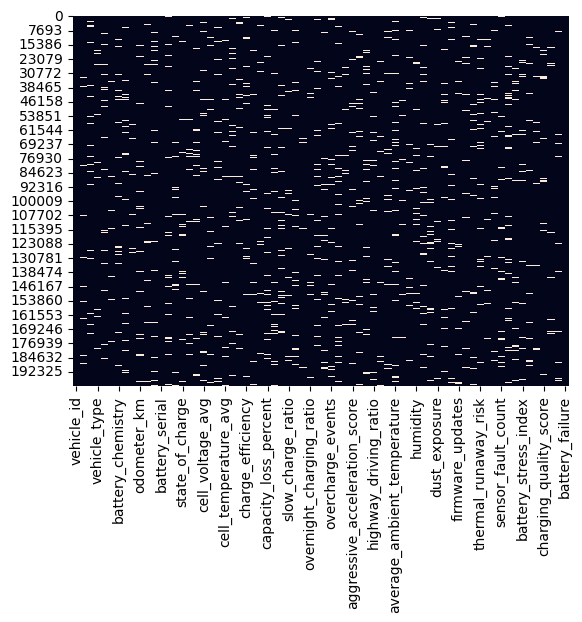

In [ ]:
sns.heatmap(df.isnull(),cbar=False)
plt.show()

In [ ]:
categorical_cols = df.select_dtypes(include=['object']).columns
print(categorical_cols)

Index(['vehicle_id', 'vehicle_brand', 'vehicle_model', 'vehicle_type',
       'battery_manufacturer', 'battery_chemistry', 'drive_type',
       'fleet_or_private', 'battery_serial', 'terrain_type'],
      dtype='object')


In [ ]:
numerical_cols = df.select_dtypes(include=['int64','float64']).columns
print(numerical_cols)

Index(['manufacturing_year', 'battery_capacity_kwh', 'odometer_km',
       'vehicle_age_years', 'cycle_count', 'battery_health_percent',
       'state_of_charge', 'depth_of_discharge', 'state_of_health',
       'cell_voltage_avg', 'cell_voltage_std', 'pack_voltage',
       'cell_temperature_avg', 'cell_temperature_max', 'internal_resistance',
       'charge_efficiency', 'discharge_efficiency', 'remaining_capacity',
       'capacity_loss_percent', 'charging_cycles_last_month',
       'fast_charge_ratio', 'slow_charge_ratio', 'average_charge_power_kw',
       'average_charging_time', 'overnight_charging_ratio',
       'home_charging_ratio', 'charging_interruptions', 'overcharge_events',
       'average_speed', 'average_trip_distance',
       'aggressive_acceleration_score', 'hard_braking_score',
       'regenerative_braking_usage', 'highway_driving_ratio',
       'city_driving_ratio', 'daily_distance', 'average_ambient_temperature',
       'maximum_temperature', 'minimum_temperature', 'h

In [ ]:
for col in categorical_cols:
  df[col] = df[col].fillna(df[col].mode()[0])

for col in numerical_cols:
  df[col] = df[col].fillna(df[col].mean().round(2))

In [ ]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows',None)

print(df.isnull().sum())

vehicle_id                         0
vehicle_brand                      0
vehicle_model                      0
vehicle_type                       0
manufacturing_year                 0
battery_manufacturer               0
battery_chemistry                  0
battery_capacity_kwh               0
drive_type                         0
odometer_km                        0
vehicle_age_years                  0
fleet_or_private                   0
battery_serial                     0
cycle_count                        0
battery_health_percent             0
state_of_charge                    0
depth_of_discharge                 0
state_of_health                    0
cell_voltage_avg                   0
cell_voltage_std                   0
pack_voltage                       0
cell_temperature_avg               0
cell_temperature_max               0
internal_resistance                0
charge_efficiency                  0
discharge_efficiency               0
remaining_capacity                 0
c

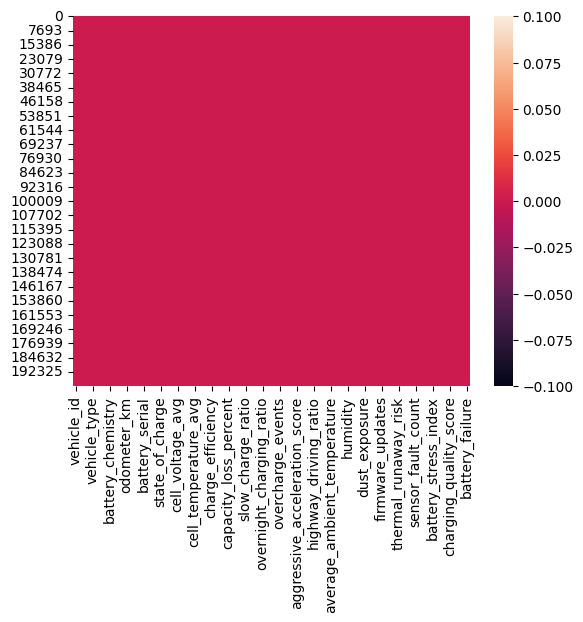

In [ ]:
sns.heatmap(df.isnull())
plt.show()

In [ ]:
df.head(50)

,vehicle_id,vehicle_brand,vehicle_model,vehicle_type,manufacturing_year,battery_manufacturer,battery_chemistry,battery_capacity_kwh,drive_type,odometer_km,vehicle_age_years,fleet_or_private,battery_serial,cycle_count,battery_health_percent,state_of_charge,depth_of_discharge,state_of_health,cell_voltage_avg,cell_voltage_std,pack_voltage,cell_temperature_avg,cell_temperature_max,internal_resistance,charge_efficiency,discharge_efficiency,remaining_capacity,capacity_loss_percent,charging_cycles_last_month,fast_charge_ratio,slow_charge_ratio,average_charge_power_kw,average_charging_time,overnight_charging_ratio,home_charging_ratio,charging_interruptions,overcharge_events,average_speed,average_trip_distance,aggressive_acceleration_score,hard_braking_score,regenerative_braking_usage,highway_driving_ratio,city_driving_ratio,daily_distance,average_ambient_temperature,maximum_temperature,minimum_temperature,humidity,altitude,terrain_type,dust_exposure,last_service_days,cooling_system_health,firmware_updates,previous_faults,maintenance_score,thermal_runaway_risk,voltage_imbalance,temperature_variance,sensor_fault_count,BMS_warning_count,abnormal_voltage_events,battery_stress_index,aging_score,thermal_health_score,charging_quality_score,driving_stress_score,predicted_remaining_life_cycles,battery_failure
0,EV100000,Nissan,Leaf,SUV,2019.000000,CATL,LMO,82.540000,RWD,98163.000000,6.940000,Private,BAT-91869505,250.000000,73.61,85.230000,26.340000,72.93000,3.288515,0.018290,934.420000,-15.660000,-10.040000,0.65850,94.630000,80.080000,60.760000,26.390000,4.00000,0.206000,0.797000,25.460000,212.200000,0.543000,0.675000,0.000000,2.0,58.000000,38.700000,0.000000,7.000000,69.4,0.352,0.676000,50.600000,-14.30000,-5.900000,-21.5000,100.000000,400.200000,Flat,20.400000,159.000000,79.300000,2.000000,0.000000,94.8,48.700000,15.300000,5.280000,2.000000,3.000000,0.0,0.00000,53.500000,66.000000,65.200000,0.000000,401.000000,0
1,EV100001,Audi,e-tron,Sedan,2018.000000,Samsung SDI,NMC,64.170000,AWD,113600.000000,7.790000,Private,BAT-67968204,256.000000,85.77,49.120000,44.830000,86.71000,3.365800,0.015180,841.460000,21.670459,34.300000,0.52060,95.160000,94.950000,55.040000,14.230000,3.00000,0.417000,0.543000,55.830000,68.500000,0.340293,0.708000,0.000000,2.0,30.700000,29.400000,36.300000,33.100000,80.7,0.353,0.661000,50.600000,26.40000,44.600000,18.8000,72.900000,702.700000,Hilly,15.700000,193.000000,73.300000,3.000000,0.000000,100.0,48.600000,9.420000,7.190000,0.000000,3.000000,0.0,51.00000,38.800000,67.800000,46.300000,40.900000,1094.000000,0
2,EV100002,Toyota,bZ4X,Van,2018.000000,Guoxuan,NMC,90.920000,RWD,242253.000000,7.850000,Fleet,BAT-82263437,556.000000,72.37,54.847079,33.650000,72.17000,3.415200,0.017473,853.810000,16.830000,31.370000,0.61350,92.210000,88.870000,65.800000,27.630000,7.00000,0.624000,0.379000,55.380000,120.500000,0.416000,0.449000,0.000000,2.0,60.500000,40.000000,27.600000,9.800000,71.0,0.374,0.623000,101.300000,9.50000,13.000000,2.4000,57.800000,687.400000,Flat,22.900000,193.000000,73.800000,3.000000,1.000000,72.2,53.200000,18.860000,20.750000,4.000000,1.000000,0.0,36.20000,66.100000,48.600000,0.000000,6.500000,645.000000,0
3,EV100003,Volkswagen,ID.3,Hatchback,2022.000000,CATL,NMC,47.350000,AWD,83700.000000,6.495245,Private,BAT-92487292,353.000000,85.11,54.320000,37.730000,87.29702,3.420200,0.015180,739.430000,-1.100000,6.250000,0.41440,94.260000,84.690000,40.300000,14.890000,10.00000,0.417000,0.559000,39.190000,83.300000,0.336000,0.760000,0.000000,0.0,65.600000,29.900000,12.800000,10.100000,68.2,0.379,0.599000,58.200000,-4.20000,2.000000,-22.5000,47.300000,752.200000,Hilly,59.000000,60.000000,88.300000,0.000000,0.000000,95.4,53.600000,12.990000,9.040000,0.000000,3.000000,1.0,23.40000,32.500000,58.200000,50.989061,40.948318,867.000000,0
4,EV100004,Tesla,Model X,Crossover,2015.000000,BYD Battery,NMC,68.040000,FWD,88784.000000,11.130000,Private,BAT-99314176,287.000000,87.40,62.730000,65.290000,86.17000,3.455600,0.021110,863.900000,29.710

In [ ]:
dropped_cols = ['vehicle_id','battery_serial','vehicle_model']

df = df.drop(columns=dropped_cols)

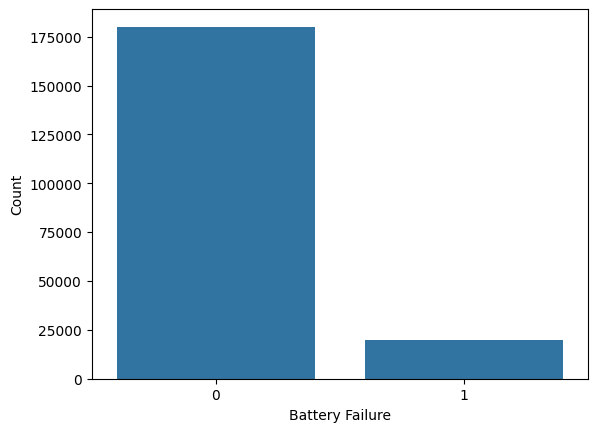

In [ ]:
sns.countplot(data=df,x='battery_failure')
plt.xlabel('Battery Failure')
plt.ylabel('Count')
plt.show()

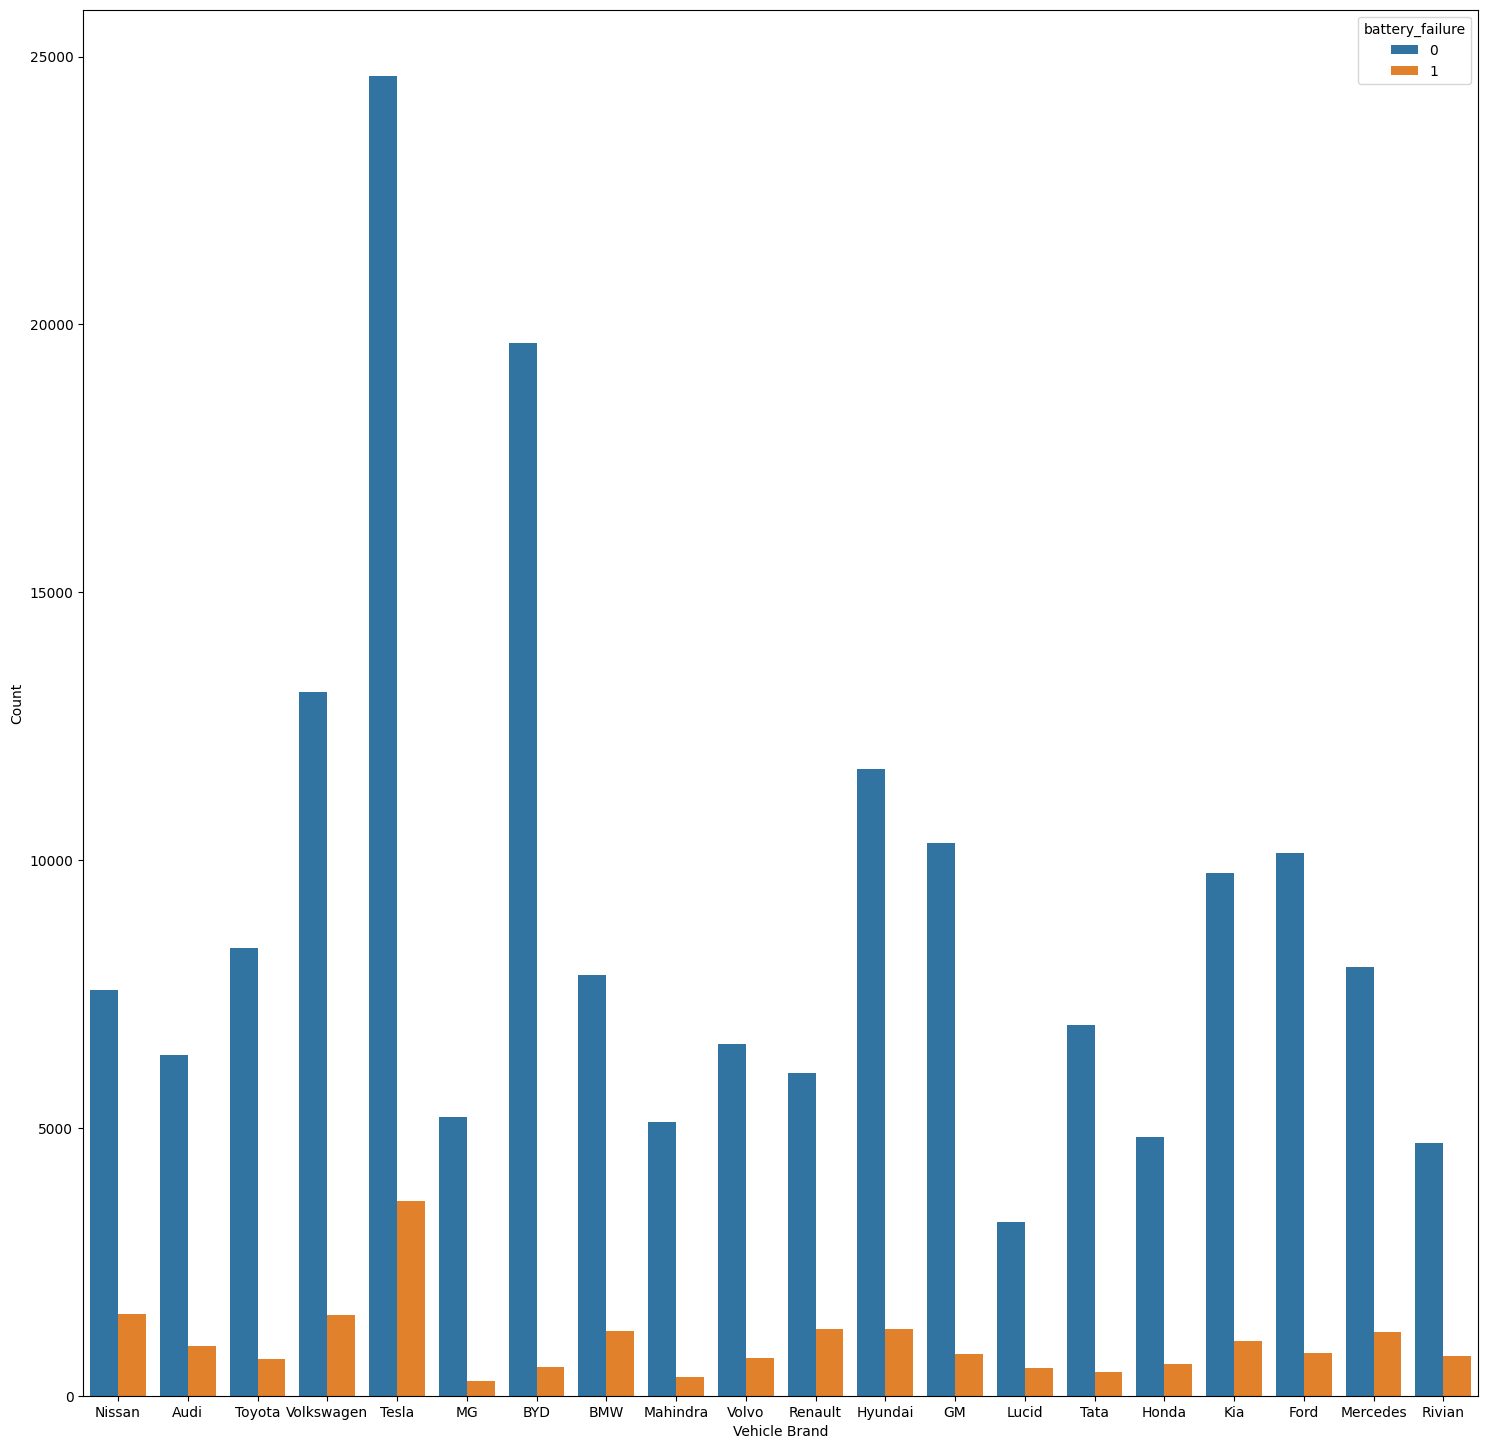

In [ ]:
plt.figure(figsize=(18,18))
sns.countplot(data=df,x='vehicle_brand',hue='battery_failure')
plt.xlabel('Vehicle Brand')
plt.ylabel('Count')
plt.show()

In [ ]:
df['terrain_type'].unique()

array(['Flat', 'Hilly', 'Coastal', 'Desert', 'Mountainous'], dtype=object)

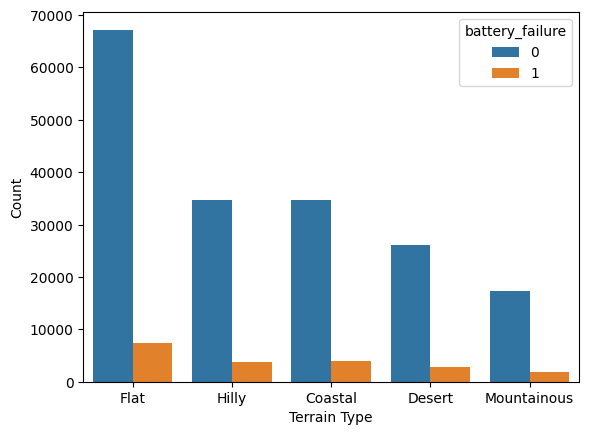

In [ ]:
sns.countplot(data=df,x='terrain_type',hue='battery_failure')
plt.xlabel('Terrain Type')
plt.ylabel('Count')
plt.show()

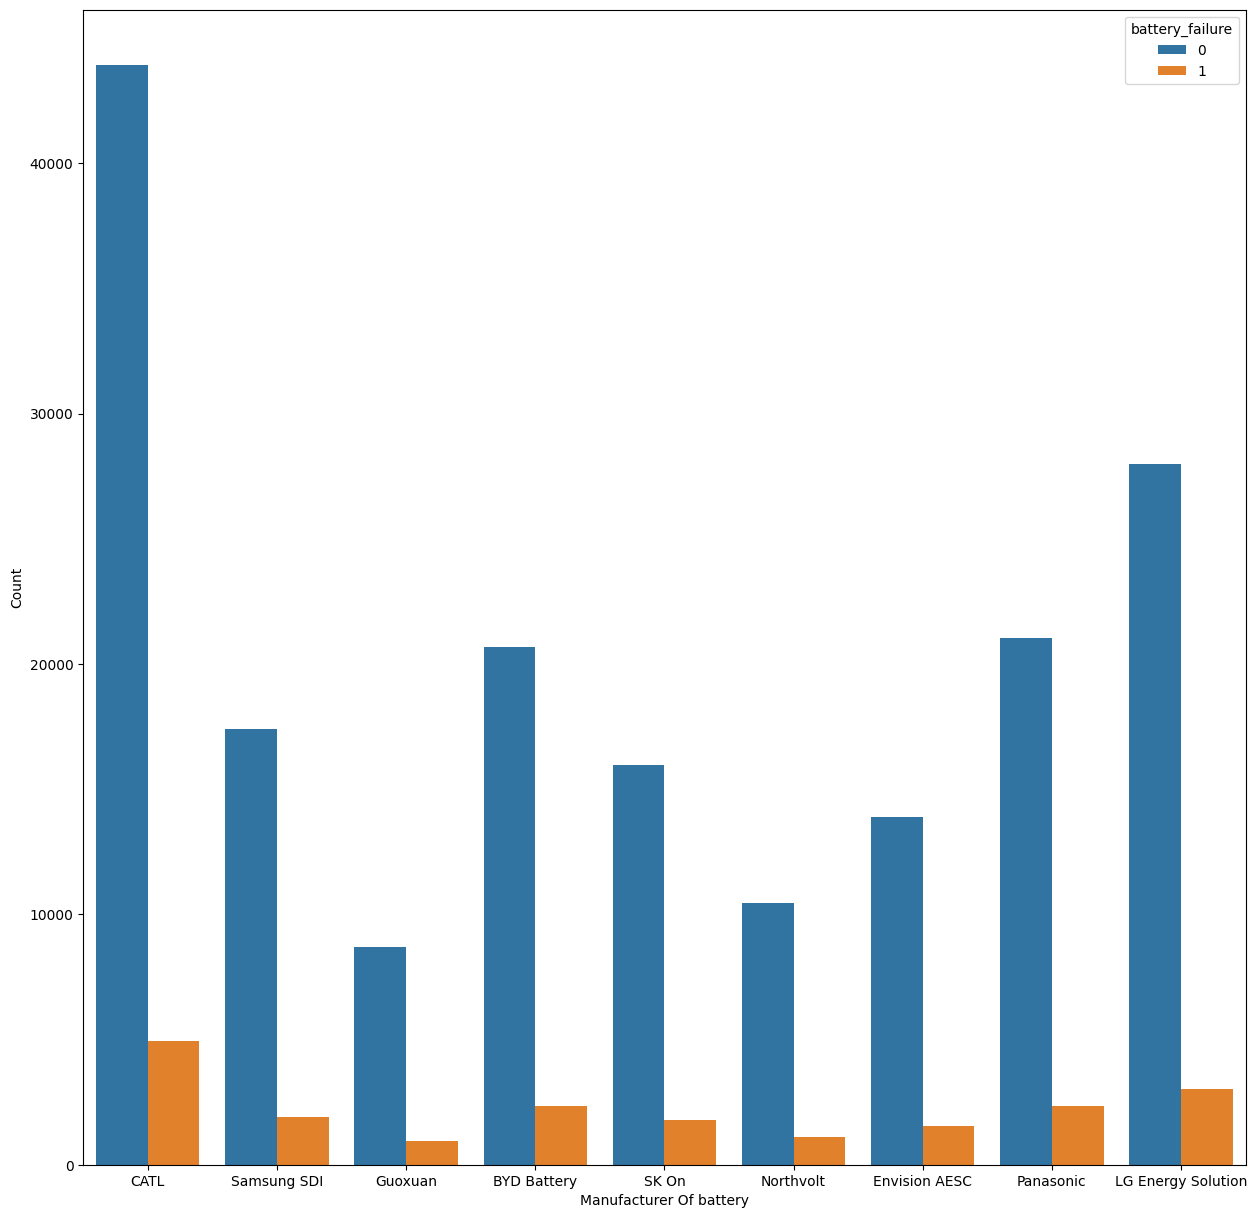

In [ ]:
plt.figure(figsize=(15,15))
sns.countplot(data=df,x='battery_manufacturer',hue='battery_failure')
plt.xlabel('Manufacturer Of battery')
plt.ylabel('Count')
plt.show()

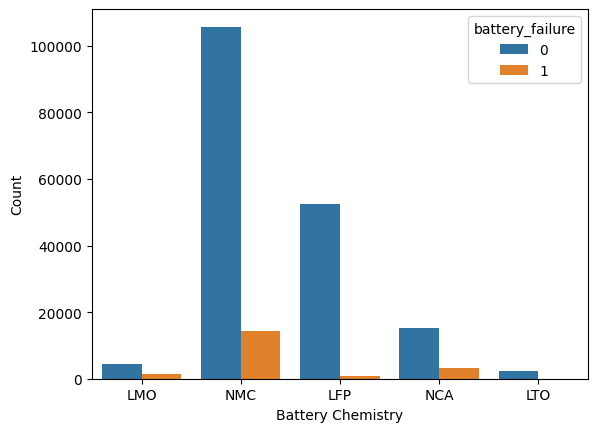

In [ ]:
sns.countplot(data=df,x='battery_chemistry',hue='battery_failure')
plt.xlabel('Battery Chemistry')
plt.ylabel('Count')
plt.show()

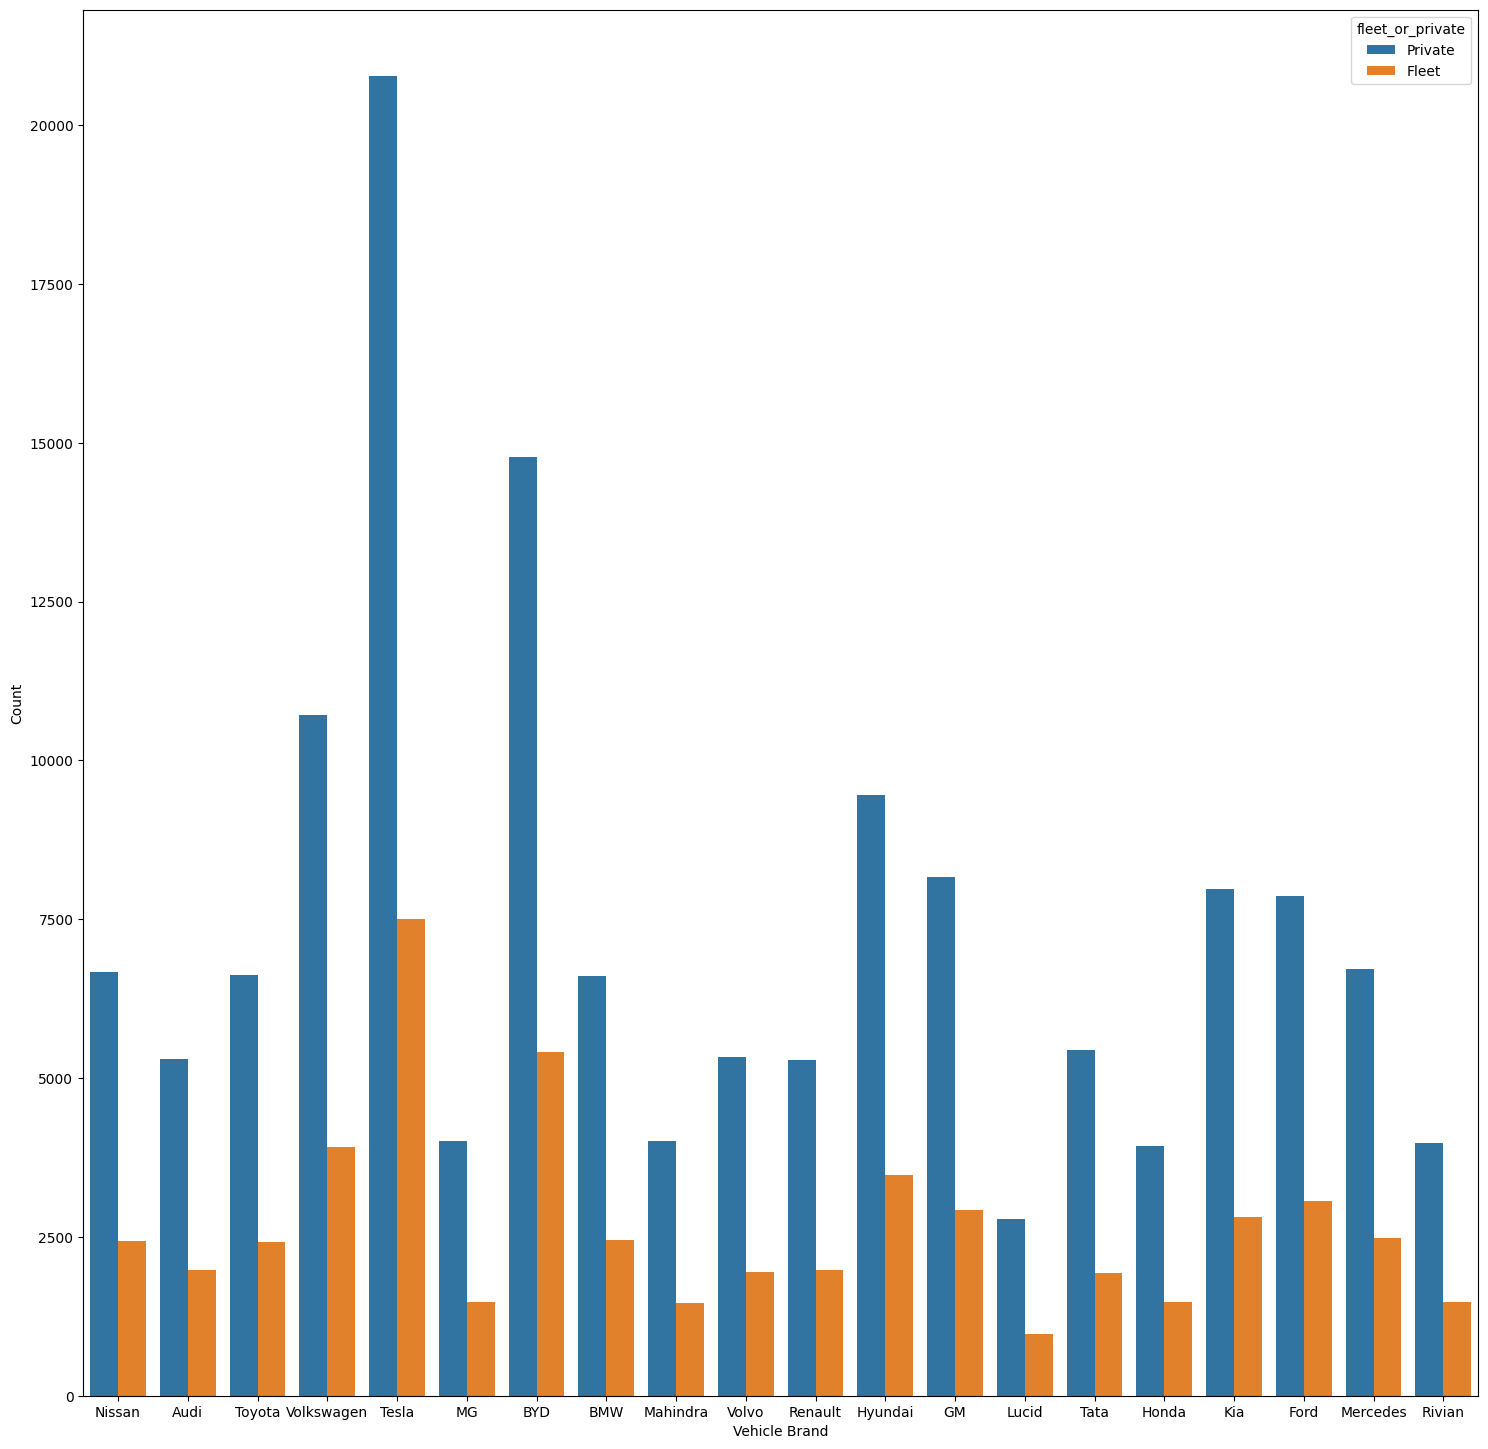

In [ ]:
plt.figure(figsize=(18,18))
sns.countplot(data=df,x='vehicle_brand',hue='fleet_or_private')
plt.xlabel('Vehicle Brand')
plt.ylabel('Count')
plt.show()

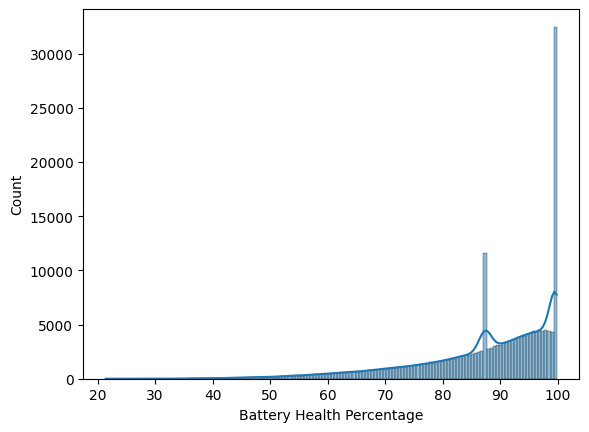

In [ ]:
sns.histplot(df['battery_health_percent'],kde=True)
plt.xlabel('Battery Health Percentage')
plt.ylabel('Count')
plt.show()

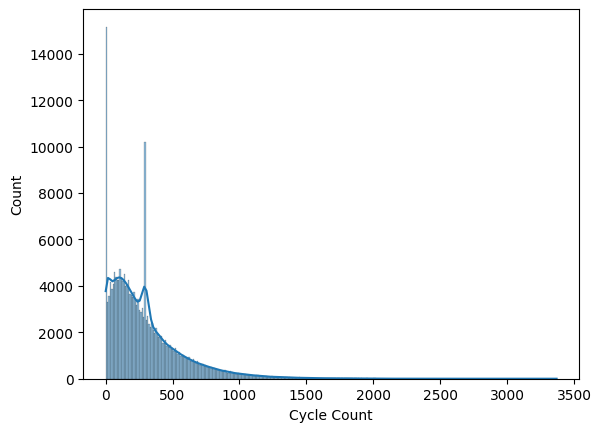

In [ ]:
sns.histplot(df['cycle_count'],kde=True)
plt.xlabel('Cycle Count')
plt.ylabel('Count')
plt.show()

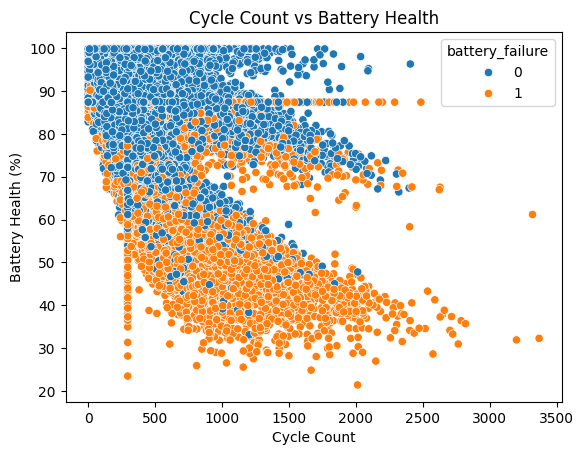

In [ ]:
sns.scatterplot(data=df, x='cycle_count', y='battery_health_percent',hue='battery_failure')
plt.xlabel('Cycle Count')
plt.ylabel('Battery Health (%)')
plt.title('Cycle Count vs Battery Health')
plt.show()

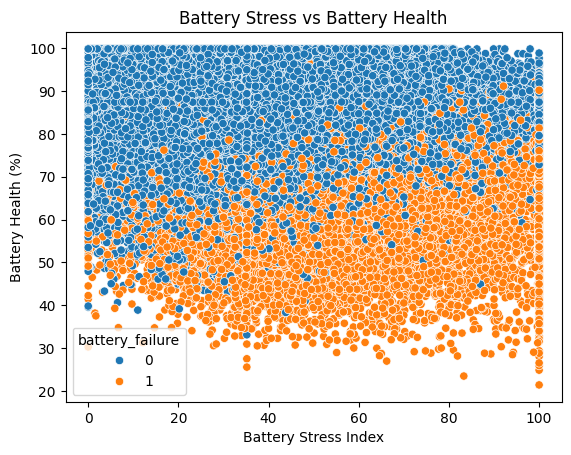

In [ ]:
sns.scatterplot(data=df, x='battery_stress_index', y='battery_health_percent',hue='battery_failure')
plt.xlabel('Battery Stress Index')
plt.ylabel('Battery Health (%)')
plt.title('Battery Stress vs Battery Health')
plt.show()

In [ ]:
from sklearn.preprocessing import LabelEncoder

categorical_cols = df.select_dtypes('object').columns

for cols in categorical_cols:
  le = LabelEncoder()
  df[cols] = le.fit_transform(df[cols])

  print(f'\n{cols}:')
  for value,numbers in zip(le.classes_, le.transform(le.classes_)):
    print(f"{value} -> {numbers}")




vehicle_brand:
Audi -> 0
BMW -> 1
BYD -> 2
Ford -> 3
GM -> 4
Honda -> 5
Hyundai -> 6
Kia -> 7
Lucid -> 8
MG -> 9
Mahindra -> 10
Mercedes -> 11
Nissan -> 12
Renault -> 13
Rivian -> 14
Tata -> 15
Tesla -> 16
Toyota -> 17
Volkswagen -> 18
Volvo -> 19

vehicle_type:
Crossover -> 0
Hatchback -> 1
SUV -> 2
Sedan -> 3
Truck -> 4
Van -> 5

battery_manufacturer:
BYD Battery -> 0
CATL -> 1
Envision AESC -> 2
Guoxuan -> 3
LG Energy Solution -> 4
Northvolt -> 5
Panasonic -> 6
SK On -> 7
Samsung SDI -> 8

battery_chemistry:
LFP -> 0
LMO -> 1
LTO -> 2
NCA -> 3
NMC -> 4

drive_type:
AWD -> 0
FWD -> 1
RWD -> 2

fleet_or_private:
Fleet -> 0
Private -> 1

terrain_type:
Coastal -> 0
Desert -> 1
Flat -> 2
Hilly -> 3
Mountainous -> 4


In [ ]:
df.head(10)

,vehicle_brand,vehicle_type,manufacturing_year,battery_manufacturer,battery_chemistry,battery_capacity_kwh,drive_type,odometer_km,vehicle_age_years,fleet_or_private,cycle_count,battery_health_percent,state_of_charge,depth_of_discharge,state_of_health,cell_voltage_avg,cell_voltage_std,pack_voltage,cell_temperature_avg,cell_temperature_max,internal_resistance,charge_efficiency,discharge_efficiency,remaining_capacity,capacity_loss_percent,charging_cycles_last_month,fast_charge_ratio,slow_charge_ratio,average_charge_power_kw,average_charging_time,overnight_charging_ratio,home_charging_ratio,charging_interruptions,overcharge_events,average_speed,average_trip_distance,aggressive_acceleration_score,hard_braking_score,regenerative_braking_usage,highway_driving_ratio,city_driving_ratio,daily_distance,average_ambient_temperature,maximum_temperature,minimum_temperature,humidity,altitude,terrain_type,dust_exposure,last_service_days,cooling_system_health,firmware_updates,previous_faults,maintenance_score,thermal_runaway_risk,voltage_imbalance,temperature_variance,sensor_fault_count,BMS_warning_count,abnormal_voltage_events,battery_stress_index,aging_score,thermal_health_score,charging_quality_score,driving_stress_score,predicted_remaining_life_cycles,battery_failure
0,12,2,2019.0,1,1,82.54,2,98163.0,6.94,1,250.0,73.61,85.23,26.34,72.93,3.2900,0.01829,934.42,-15.66,-10.04,0.6585,94.63,80.08,60.76,26.39,4.0,0.206,0.797,25.46,212.2,0.543,0.675,0.0,2.0,58.0,38.7,0.0,7.0,69.4,0.352,0.676,50.6,-14.30,-5.90,-21.5,100.00,400.2,2,20.4,159.00,79.30,2.0,0.0,94.8,48.7,15.30,5.28,2.0,3.0,0.0,0.00,53.50,66.0,65.20,0.00,401.0,0
1,0,3,2018.0,8,4,64.17,0,113600.0,7.79,1,256.0,85.77,49.12,44.83,86.71,3.3658,0.01518,841.46,21.67,34.30,0.5206,95.16,94.95,55.04,14.23,3.0,0.417,0.543,55.83,68.5,0.340,0.708,0.0,2.0,30.7,29.4,36.3,33.1,80.7,0.353,0.661,50.6,26.40,44.60,18.8,72.90,702.7,3,15.7,193.00,73.30,3.0,0.0,100.0,48.6,9.42,7.19,0.0,3.0,0.0,51.00,38.80,67.8,46.30,40.90,1094.0,0
2,17,5,2018.0,3,4,90.92,2,242253.0,7.85,0,556.0,72.37,54.85,33.65,72.17,3.4152,0.02000,853.81,16.83,31.37,0.6135,92.21,88.87,65.80,27.63,7.0,0.624,0.379,55.38,120.5,0.416,0.449,0.0,2.0,60.5,40.0,27.6,9.8,71.0,0.374,0.623,101.3,9.50,13.00,2.4,57.80,687.4,2,22.9,193.00,73.80,3.0,1.0,72.2,53.2,18.86,20.75,4.0,1.0,0.0,36.20,66.10,48.6,0.00,6.50,645.0,0
3,18,1,2022.0,1,4,47.35,0,83700.0,6.50,1,353.0,85.11,54.32,37.73,87.30,3.4202,0.01518,739.43,-1.10,6.25,0.4144,94.26,84.69,40.30,14.89,10.0,0.417,0.559,39.19,83.3,0.336,0.760,0.0,0.0,65.6,29.9,12.8,10.1,68.2,0.379,0.599,58.2,-4.20,2.00,-22.5,47.30,752.2,3,59.0,60.00,88.30,0.0,0.0,95.4,53.6,12.99,9.04,0.0,3.0,1.0,23.40,32.50,58.2,50.99,40.95,867.0,0
4,16,0,2015.0,0,4,68.04,1,88784.0,11.13,1,287.0,87.40,62.73,65.29,86.17,3.4556,0.02111,863.90,29.71,31.20,0.5663,96.60,93.78,59.47,12.60,5.0,0.250,0.755,44.07,118.2,0.454,0.586,0.0,0.0,61.6,8.1,61.0,35.4,34.2,0.000,1.000,27.5,17.98,29.80,10.3,30.60,283.6,0,33.9,217.35,48.20,19.0,3.0,100.0,62.1,25.29,10.55,3.0,2.0,1.0,51.20,45.40,51.0,50.99,100.00,1090.0,0
5,9,2,2018.0,8,0,74.97,0,156939.0,8.06,1,483.0,93.80,28.97,40.14,91.07,2.8677,0.01412,716.92,32.04,42.23,0.6265,95.66,96.41,70.32,6.20,6.0,0.529,0.475,59.89,92.5,0.149,0.479,0.0,0.0,60.6,29.4,70.8,40.0,34.9,0.639,0.344,67.1,24.30,28.20,17.8,69.10,124.8,3,32.0,308.00,67.00,7.0,1.0,86.0,23.1,15.12,17.89,0.0,1.0,0.0,49.20,27.70,70.7,49.60,100.00,3258.0,0
6,12,2,2019.0,0,4,76.24,1,185719.0,6.91,0,428.0,76.96,52.06,45.85,80.22,3.4145,0.01689,853.62,26.07,36.90,0.5715,92.88,92.26,73.12,23.04,6.0,0.500,0.489,47.61,134.3,0.200,0.405,2.0,1.0,29.2,32.3,49.6,52.4,54.2,0.610,0.401,96.1,17.20,27.60,9.9,54.99,479.3,3,41.8,162.00,79.80,5.4,0.0,92.2,58.4,13.18,20.93,0.0,5.0,0.0,52.90,29.91,48.8,2.70,83.40,784.0,0
7,12,2,2016.0,1,4,92.36,0,110334.0,10.31,1,195.0,79.89,57.20,55.05,79.21,3.4229,0.02046,855.73,21.67,15.43,0.5637,97.82,86.28,73.79,20.11,2.0,0.760,0.236,64.47,103.8,0.550,0.797,3.0,1.0,47.3,12.9,31.3,28.8,59.2,0.317,0.626,36.8,2.90,27.02,-8.7,43.50,91

In [ ]:
df.to_csv('encoded_cleaned_data.csv',index=False)